# BBO Capstone: weekly analysis notebook

Imperial College Business School, Professional Certificate in ML and AI. Stage 2 black-box optimisation challenge, thirteen query rounds (Modules 12 to 24).

This notebook is the single analysis tool used every week. The full query history (every input submitted and every output the portal returned, rounds 1 to 13) lives in the `ROUNDS` list in section 1, so every model below is re-derived from the history and any round can be replayed with the data that was available at the time: shorten `ROUNDS` to the first *k* entries and re-run.

Workflow each week:

1. **Record** the returned (x, y) pairs in `ROUNDS`
2. **Diagnose** each function (log-scale check, ranges, correlations)
3. **Visualise** what can be visualised
4. **Estimate gradients** near the incumbent
5. **Fit GP + expected improvement** (the model's suggestion), with the SVM fence on the high-dimensional functions
6. **Compare** model suggestion, momentum candidate and structural reasoning, check stability across seeds, then decide

The single most important habit, learned the hard way in round 1: **always look at the outputs on a log scale before modelling.** Function 1's readings looked like zeros but spanned 225 orders of magnitude; the signal was there all along, invisible on a raw scale.

Section 9 at the end summarises the thirteen rounds: best-so-far per function, the round each best arrived in, and the decider tag for every query. A flat CSV of the same history is in `query_log.csv`.


## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
from scipy.stats import norm
from scipy.optimize import minimize

np.set_printoptions(precision=4, suppress=True)
DATA = 'initial_data'   # folder with function_1..function_8/initial_inputs.npy & initial_outputs.npy

## 1. Record each round's queries and results

`ROUNDS` is the source of truth. One dict per round; `x` holds the submitted inputs per function, `y` the scalar the portal returned. Values are exactly as submitted and returned (see the weekly portal emails and `query_log.csv`).

`DECIDED_BY` records what chose each query: `surrogate` (GP + EI), `surrogate-log` (same, fitted on log y), `svm-filter` (GP restricted to the SVM fence), `structural` (hypothesis from the function description), `trend` (extrapolating a measured trend after the model lost its vote), `exploration` (deliberate probe of an unsampled region), `repeat` (incumbent re-queried to certify it). The tags were reconstructed in Module 25 from the weekly reflections, so treat them as a faithful summary rather than a contemporaneous log.


In [2]:
ROUNDS = [
    # ---- Round 1 ----
    {'x': {1:[0.08, 0.9], 2:[0.7, 0.5], 3:[0.468782, 0.581931, 0.282864], 4:[0.52737, 0.436077, 0.336338, 0.317217], 5:[0.414656, 0.79259, 0.818309, 0.999999], 6:[0.464911, 0.24234, 0.574744, 0.999999, 0.0], 7:[0.0, 0.269851, 0.3472, 0.326982, 0.318806, 0.875053], 8:[0.064158, 0.008508, 0.123182, 0.0, 0.999999, 0.381815, 0.031592, 0.58037]},
     'y': {1:3.1646078818156056e-241, 2:0.6429637310940071, 3:-0.09281112712055184, 4:-1.9793546745462396, 5:1388.5156258169561, 6:-0.53946609584505, 7:1.7622787656247987, 8:9.8640427237925}},
    # ---- Round 2 ----
    {'x': {1:[0.577, 0.577], 2:[0.7, 0.71], 3:[0.551994, 0.650585, 0.430877], 4:[0.47694, 0.443354, 0.246876, 0.385434], 5:[0.1, 0.84, 0.98, 0.999999], 6:[0.541, 0.18, 0.598, 0.875, 0.13], 7:[0.177226, 0.388067, 0.247383, 0.310025, 0.324054, 0.999999], 8:[0.156448, 0.229796, 0.063575, 0.200512, 0.999999, 0.960702, 0.214065, 0.515382]},
     'y': {1:9.037147466048306e-05, 2:0.624849273684726, 3:-0.014664579275023532, 4:-2.6481386984914788, 5:2652.835603960075, 6:-0.48927779087397527, 7:0.9784297393926809, 8:9.7381137391101}},
    # ---- Round 3 ----
    {'x': {1:[0.554, 0.555], 2:[0.95, 0.7], 3:[0.58, 0.6, 0.54], 4:[0.431, 0.4127, 0.3237, 0.3549], 5:[0.001, 0.8, 0.999999, 0.999999], 6:[0.52, 0.1, 0.7, 0.96, 0.06], 7:[0.0, 0.513, 0.421, 0.378, 0.364, 0.629], 8:[0.057011, 0.157671, 0.219278, 0.075568, 0.995306, 0.431232, 0.279704, 0.064496]},
     'y': {1:4.655159017771198e-08, 2:-0.057425225266941465, 3:-0.022584096348090603, 4:0.0677700852497769, 5:2621.5251128410623, 6:-0.6725915226293955, 7:1.541619808717913, 8:9.9016100777654}},
    # ---- Round 4 ----
    {'x': {1:[0.59256, 0.647087], 2:[0.719083, 0.0], 3:[0.999999, 0.0, 0.78293], 4:[0.376347, 0.414508, 0.41858, 0.417207], 5:[0.0, 0.95, 0.999999, 0.999999], 6:[0.498503, 0.346809, 0.496494, 0.756999, 0.051729], 7:[0.0, 0.043973, 0.764721, 0.597187, 0.0, 0.972207], 8:[0.194521, 0.04337, 0.191716, 0.000927, 0.963113, 0.417436, 0.163658, 0.661463]},
     'y': {1:0.014062029020830596, 2:0.5123092830069946, 3:-0.16091516763820124, 4:0.6816214776878522, 5:3819.715023825854, 6:-0.2923214108021201, 7:0.33756078743009515, 8:9.9139732594756}},
    # ---- Round 5 ----
    {'x': {1:[0.638966, 0.626916], 2:[0.1, 0.9], 3:[0.386397, 0.976462, 0.0], 4:[0.391, 0.508, 0.3867, 0.4119], 5:[0.0, 0.999999, 0.999999, 0.999999], 6:[0.466679, 0.332528, 0.555313, 0.780451, 0.009062], 7:[0.0, 0.95, 0.95, 0.05, 0.3, 0.9], 8:[0.05, 0.76, 0.14, 0.999999, 0.95, 0.02, 0.06, 0.86]},
     'y': {1:1.5269622408267942, 2:0.05180137682262144, 3:-0.14238782703697908, 4:-1.6161503376857875, 5:4440.480873479282, 6:-0.237822127299094, 7:0.08816220131405664, 8:8.612491699999}},
    # ---- Round 6 ----
    {'x': {1:[0.65, 0.62], 2:[0.688338, 0.167053], 3:[0.0, 0.999999, 0.387517], 4:[0.398621, 0.345798, 0.387083, 0.394624], 5:[0.05, 0.999999, 0.999999, 0.999999], 6:[0.461125, 0.323552, 0.919614, 0.688576, 0.0], 7:[0.0, 0.19618, 0.284461, 0.305756, 0.329854, 0.644562], 8:[0.120541, 0.143897, 0.101491, 0.129505, 0.990609, 0.582922, 0.154359, 0.663657]},
     'y': {1:0.5246056020513356, 2:0.5699665261791884, 3:-0.06607301134724677, 4:0.18910765317842548, 5:4440.569945829619, 6:-0.521139445653098, 7:2.5705483075378304, 8:9.9666471771096}},
    # ---- Round 7 ----
    {'x': {1:[0.6445, 0.6235], 2:[0.76, 0.55], 3:[0.563, 0.651, 0.416], 4:[0.308696, 0.396405, 0.376468, 0.387884], 5:[0.2, 0.999999, 0.999999, 0.999999], 6:[0.380699, 0.243705, 0.54403, 0.713924, 0.0], 7:[0.0, 0.159, 0.253, 0.295, 0.335, 0.529], 8:[0.097789, 0.238698, 0.059848, 0.110771, 0.839171, 0.464839, 0.233797, 0.962661]},
     'y': {1:1.0051544921868911, 2:0.2821019468930076, 3:-0.013511084732118175, 4:-1.4218869648758914, 5:4447.842132156064, 6:-0.43235358860077694, 7:2.2059827326481973, 8:9.9583798099494}},
    # ---- Round 8 ----
    {'x': {1:[0.632, 0.6315], 2:[0.9, 0.15], 3:[0.999999, 0.086681, 0.421518], 4:[0.376, 0.415, 0.48, 0.48], 5:[0.6, 0.999999, 0.999999, 0.999999], 6:[0.467, 0.333, 0.555, 0.9, 0.0], 7:[0.0, 0.12, 0.22, 0.3, 0.335, 0.66], 8:[0.1, 0.1, 0.1, 0.03, 0.999999, 0.7, 0.15, 0.95]},
     'y': {1:1.90281555453299, 2:-0.002770751436162705, 3:-0.07523088565814594, 4:-2.253656589905336, 5:4929.695657340682, 6:-0.43578908199448607, 7:2.478659276074948, 8:9.9031501999995}},
    # ---- Round 9 ----
    {'x': {1:[0.6288, 0.6265], 2:[0.695, 0.55], 3:[0.58, 0.655, 0.44], 4:[0.4302, 0.4117, 0.42, 0.3748], 5:[0.999999, 0.999999, 0.999999, 0.999999], 6:[0.478, 0.152, 0.496, 0.795, 0.0], 7:[0.0, 0.15, 0.28, 0.298, 0.344, 0.694], 8:[0.137, 0.176, 0.11, 0.191, 0.999999, 0.488, 0.186, 0.733]},
     'y': {1:1.9797982957265023, 2:0.5099981491896157, 3:-0.014108465083626062, 4:0.5976907632056343, 5:8662.405001248297, 6:-0.6022245202118208, 7:2.5419800422602017, 8:9.9714002999995}},
    # ---- Round 10 ----
    {'x': {1:[0.6256, 0.6214], 2:[0.708, 0.55], 3:[0.5017, 0.3124, 0.4144], 4:[0.403, 0.413, 0.4195, 0.396], 5:[0.9, 0.999999, 0.999999, 0.999999], 6:[0.467, 0.333, 0.66, 0.83, 0.0], 7:[0.0, 0.25, 0.33, 0.306, 0.33, 0.645], 8:[0.133352, 0.157522, 0.129015, 0.17066, 0.999999, 0.512597, 0.151272, 0.631596]},
     'y': {1:1.732347888552608, 2:0.6231525871188877, 3:-0.0285728407830527, 4:0.5531314202895286, 5:7073.392996815889, 6:-0.30674276416206103, 7:2.567001602866077, 8:9.9722818103339}},
    # ---- Round 11 ----
    {'x': {1:[0.6297, 0.6278], 2:[0.704, 0.5], 3:[0.483, 0.571, 0.3916], 4:[0.375, 0.4042, 0.3889, 0.4149], 5:[0.999999, 0.999999, 0.9, 0.999999], 6:[0.485, 0.335, 0.622, 0.722, 0.0], 7:[0.1, 0.196, 0.284, 0.306, 0.33, 0.645], 8:[0.134298, 0.145938, 0.115179, 0.163668, 0.999999, 0.509093, 0.18098, 0.653808]},
     'y': {1:1.990931619079835, 2:0.5346468952037856, 3:-0.008935453610601916, 4:0.39741582467041114, 5:7073.392996815889, 6:-0.22572589061810086, 7:2.8776305106442157, 8:9.9756894606651}},
    # ---- Round 12 ----
    {'x': {1:[0.6291, 0.6282], 2:[0.7, 0.6], 3:[0.483, 0.6, 0.392], 4:[0.376, 0.405, 0.419, 0.417], 5:[0.999999, 0.999999, 0.999999, 0.9], 6:[0.4701, 0.325, 0.6044, 0.7524, 0.0], 7:[0.2, 0.1431, 0.3331, 0.3014, 0.3088, 0.673], 8:[0.0843, 0.1959, 0.14, 0.1137, 0.95, 0.5046, 0.2286, 0.629]},
     'y': {1:1.997940465224263, 2:0.574977897809024, 3:-0.009238777759316873, 4:0.6258265261968998, 5:7073.392996815888, 6:-0.2034249818787067, 7:3.162168725421895, 8:9.98279134}},
    # ---- Round 13 ----
    {'x': {1:[0.6291, 0.6282], 2:[0.7, 0.96], 3:[0.483, 0.571, 0.3916], 4:[0.376347, 0.414508, 0.41858, 0.417207], 5:[0.999999, 0.999999, 0.999999, 0.999999], 6:[0.4854, 0.3005, 0.616, 0.756, 0.0], 7:[0.3, 0.1279, 0.3368, 0.2995, 0.3048, 0.6757], 8:[0.0843, 0.1959, 0.14, 0.1137, 0.95, 0.5046, 0.2286, 0.629]},
     'y': {1:1.997940465224263, 2:0.6407122651596344, 3:-0.02440744130902396, 4:0.6816214776878522, 5:8662.405001248297, 6:-0.3431380204000119, 7:3.0980711482687036, 8:9.98279134}},
]

# Decider tag per (round, function). Reconstructed from the weekly reflections in Module 25.
DECIDED_BY = {
 1: {1:'surrogate',2:'surrogate',3:'surrogate',4:'surrogate',5:'surrogate',6:'surrogate',7:'surrogate',8:'surrogate'},
 2: {1:'surrogate-log',2:'surrogate',3:'structural',4:'surrogate',5:'surrogate-log',6:'structural',7:'surrogate',8:'surrogate'},
 3: {1:'trend',2:'exploration',3:'structural',4:'surrogate',5:'surrogate-log',6:'structural',7:'exploration',8:'svm-filter'},
 4: {1:'trend',2:'exploration',3:'exploration',4:'surrogate',5:'trend',6:'surrogate',7:'exploration',8:'svm-filter'},
 5: {1:'trend',2:'exploration',3:'exploration',4:'surrogate',5:'trend',6:'surrogate',7:'exploration',8:'exploration'},
 6: {1:'trend',2:'surrogate',3:'exploration',4:'surrogate',5:'trend',6:'exploration',7:'surrogate',8:'svm-filter'},
 7: {1:'trend',2:'surrogate',3:'structural',4:'surrogate',5:'trend',6:'surrogate',7:'surrogate',8:'svm-filter'},
 8: {1:'trend',2:'exploration',3:'exploration',4:'surrogate',5:'trend',6:'trend',7:'surrogate',8:'exploration'},
 9: {1:'trend',2:'surrogate',3:'structural',4:'surrogate',5:'trend',6:'exploration',7:'surrogate',8:'svm-filter'},
 10:{1:'trend',2:'surrogate',3:'surrogate',4:'surrogate',5:'exploration',6:'surrogate',7:'surrogate',8:'surrogate'},
 11:{1:'trend',2:'surrogate',3:'structural',4:'surrogate',5:'exploration',6:'surrogate',7:'trend',8:'surrogate'},
 12:{1:'trend',2:'surrogate',3:'structural',4:'surrogate',5:'exploration',6:'surrogate',7:'trend',8:'surrogate'},
 13:{1:'repeat',2:'exploration',3:'repeat',4:'repeat',5:'repeat',6:'surrogate',7:'trend',8:'repeat'},
}

def load(fn):
    """Initial data plus every recorded round, in order."""
    X = np.load(f'{DATA}/function_{fn}/initial_inputs.npy')
    y = np.load(f'{DATA}/function_{fn}/initial_outputs.npy')
    for r in ROUNDS:
        if fn in r['x']:
            X = np.vstack([X, r['x'][fn]])
            y = np.append(y, r['y'][fn])
    return X, y

for fn in range(1, 9):
    X, y = load(fn)
    print(f"F{fn}: {X.shape[0]} points, {X.shape[1]}D, best y = {y.max():.6g}")


F1: 23 points, 2D, best y = 1.99794
F2: 23 points, 2D, best y = 0.642964
F3: 28 points, 3D, best y = -0.00893545
F4: 43 points, 4D, best y = 0.681621
F5: 33 points, 4D, best y = 8662.41
F6: 33 points, 5D, best y = -0.203425
F7: 43 points, 6D, best y = 3.16217
F8: 53 points, 8D, best y = 9.98279


## 2. Diagnostics — the log-scale check

For each function: how wide is the output range? If it spans many orders of magnitude,
a GP fitted on raw values will be dominated by one extreme point, and any correlation you
compute will be distorted by it. The fix is a monotone transform (log), which evens out
the spread **without changing which input is best** — so the optimisation problem is
identical, only the model's eyesight improves.

In [3]:
def diagnose(fn):
    X, y = load(fn)
    print(f"--- F{fn} ({X.shape[1]}D, {len(y)} pts) ---")
    print(f"  y range: {y.min():.4g} .. {y.max():.4g}")
    pos = y[y > 0]
    if len(pos):
        decades = np.log10(pos.max()) - np.log10(pos.min())
        print(f"  positive values span {decades:.1f} orders of magnitude"
              f"{'   <-- LOG TRANSFORM NEEDED' if decades > 2 else ''}")
    if (y <= 0).any():
        print(f"  {(y<=0).sum()} non-positive values (plain log unusable; try -log(-y) if all negative)")
    # ratio of top gap to typical gap: is the best point a real peak or a fluke?
    s = np.sort(y)[::-1]
    if len(s) > 3:
        print(f"  best {s[0]:.4g} vs 2nd {s[1]:.4g}  (gap {s[0]-s[1]:.4g})")
    return X, y

for fn in range(1, 9):
    diagnose(fn); print()

--- F1 (2D, 23 pts) ---
  y range: -0.003606 .. 1.998
  positive values span 240.8 orders of magnitude   <-- LOG TRANSFORM NEEDED
  3 non-positive values (plain log unusable; try -log(-y) if all negative)
  best 1.998 vs 2nd 1.998  (gap 0)

--- F2 (2D, 23 pts) ---
  y range: -0.06562 .. 0.643
  positive values span 1.4 orders of magnitude
  4 non-positive values (plain log unusable; try -log(-y) if all negative)
  best 0.643 vs 2nd 0.6407  (gap 0.002251)

--- F3 (3D, 28 pts) ---
  y range: -0.3989 .. -0.008935
  28 non-positive values (plain log unusable; try -log(-y) if all negative)
  best -0.008935 vs 2nd -0.009239  (gap 0.0003033)

--- F4 (4D, 43 pts) ---
  y range: -32.63 .. 0.6816
  positive values span 1.0 orders of magnitude
  35 non-positive values (plain log unusable; try -log(-y) if all negative)
  best 0.6816 vs 2nd 0.6816  (gap 0)

--- F5 (4D, 33 pts) ---
  y range: 0.1129 .. 8662
  positive values span 4.9 orders of magnitude   <-- LOG TRANSFORM NEEDED
  best 8662 vs 2nd 

## 3. Visualise

2D functions can be plotted directly. For higher dimensions, plot each coordinate against
y — a "which dimension matters?" view. Steep trends mean an influential dimension.

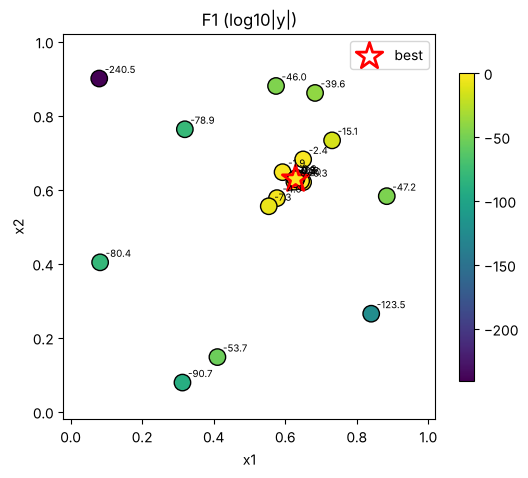

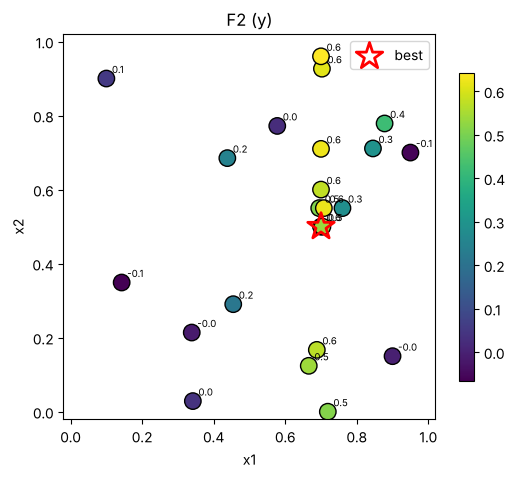

In [4]:
def plot_2d(fn, log_scale=False):
    X, y = load(fn)
    v = np.log10(np.abs(y)) if log_scale else y
    lbl = 'log10|y|' if log_scale else 'y'
    fig, ax = plt.subplots(figsize=(6,5))
    sc = ax.scatter(X[:,0], X[:,1], c=v, cmap='viridis', s=140, edgecolor='k')
    b = np.argmax(y)
    ax.scatter(*X[b], marker='*', s=400, facecolor='none', edgecolor='red', lw=2, label='best')
    for j,(px,py) in enumerate(X):
        ax.annotate(f'{v[j]:.1f}', (px,py), fontsize=7, xytext=(4,4), textcoords='offset points')
    ax.set_xlim(-.02,1.02); ax.set_ylim(-.02,1.02)
    ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.set_title(f'F{fn} ({lbl})'); ax.legend()
    fig.colorbar(sc, ax=ax, shrink=.8); plt.show()

plot_2d(1, log_scale=True)   # F1 only makes sense on a log scale
plot_2d(2)

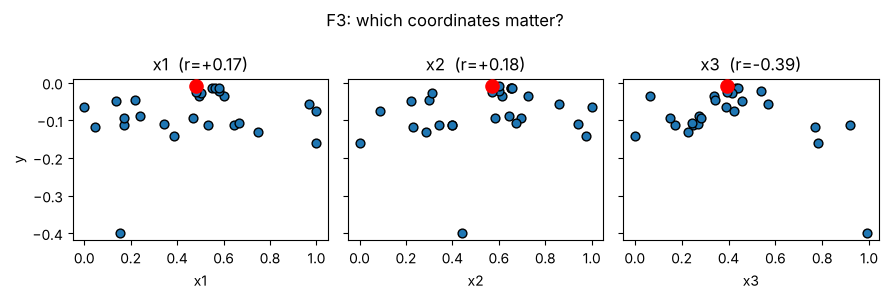

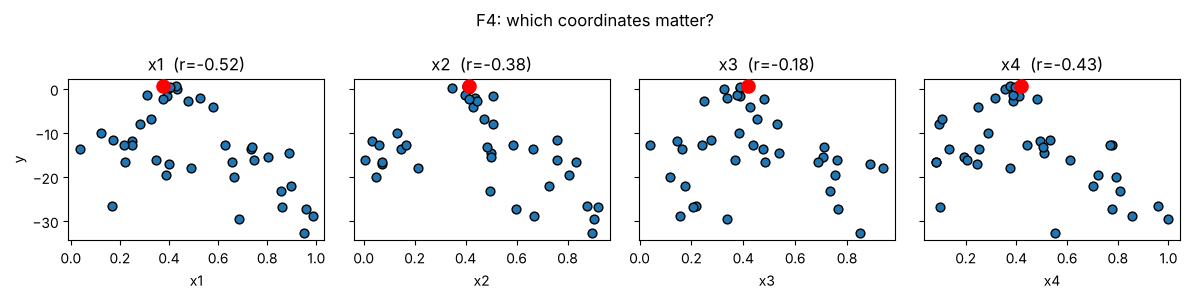

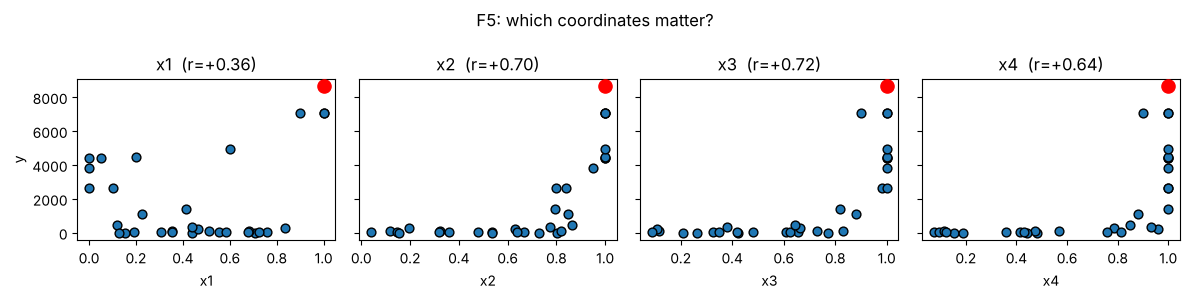

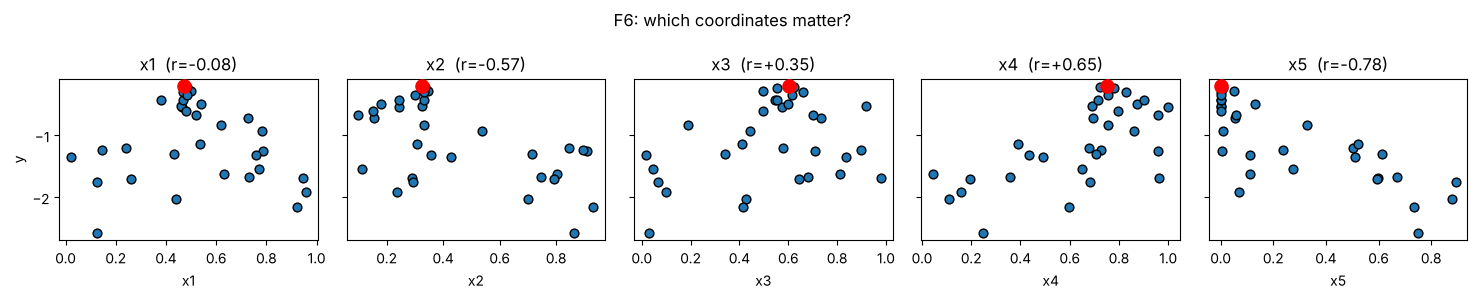

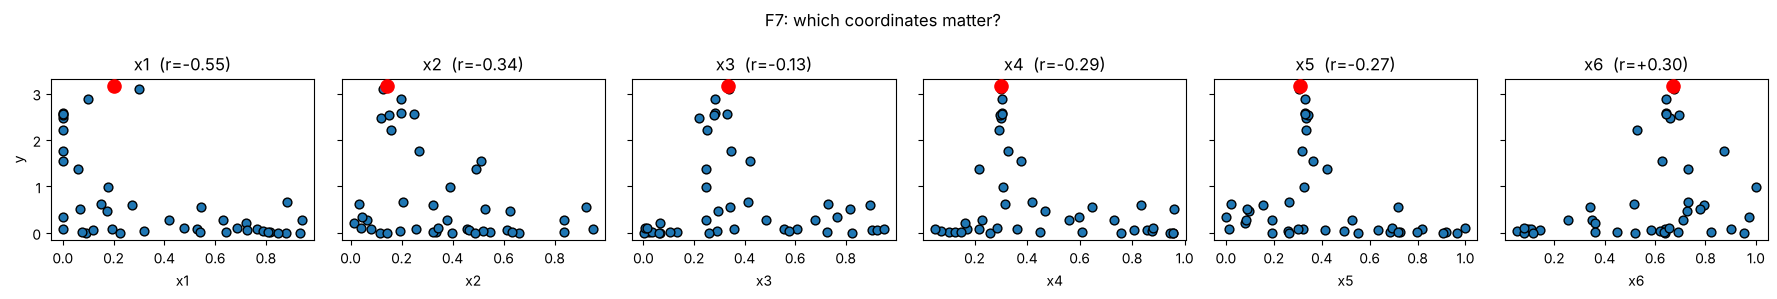

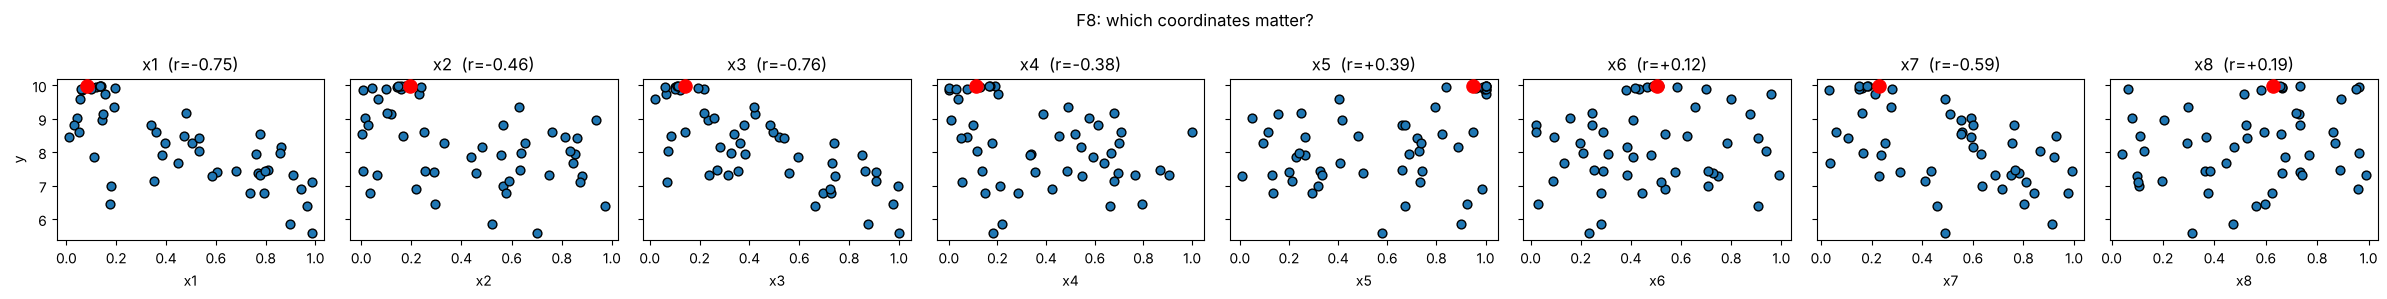

In [5]:
def plot_coords(fn, log_scale=False):
    """Each coordinate vs y. Look for visible trends = influential dimensions."""
    X, y = load(fn)
    v = np.log10(np.abs(y)) if log_scale else y
    d = X.shape[1]
    fig, axes = plt.subplots(1, d, figsize=(3*d, 3), sharey=True)
    axes = np.atleast_1d(axes)
    for i, ax in enumerate(axes):
        ax.scatter(X[:,i], v, s=40, edgecolor='k')
        ax.scatter(X[np.argmax(y), i], v[np.argmax(y)], color='red', s=90, zorder=3)
        r = np.corrcoef(X[:,i], v)[0,1]
        ax.set_title(f'x{i+1}  (r={r:+.2f})'); ax.set_xlabel(f'x{i+1}')
    axes[0].set_ylabel('log10|y|' if log_scale else 'y')
    fig.suptitle(f'F{fn}: which coordinates matter?'); fig.tight_layout(); plt.show()

for fn in [3,4,5,6,7,8]:
    plot_coords(fn)

## 4. Local gradient estimate

Fit a plane (linear model) to the points **near the incumbent** — its slope is an estimate
of the local gradient, i.e. the uphill direction. Useful as an independent sanity check on
whatever the GP suggests. If the two disagree, that is a signal to think rather than obey.

## 4b. Source triangulation (F1-style functions)

Proximity detectors decay roughly like `y ≈ peak * exp(-k * d²)` where `d` is the distance
to the source. Taking logs turns that into a **quadratic** in the coordinates: `log y` is a
downward-curving bowl centred exactly on the source. So fitting a quadratic surface to
`log|y|` and solving for its peak *locates the source* — even when every raw reading looks
like zero.

Check the eigenvalues of the Hessian `H`: **both negative** means the fit found a true
maximum (a dome). Positive values mean a saddle or a bowl, and the estimate is not trustworthy.

The `positives_only` switch matters: negative readings may belong to a different mechanism
(e.g. a negative ring around the peak), so fitting on clean positive readings alone is often
the more reliable estimate. Compare both — if they agree, you can trust the location.

In [6]:
def triangulate(fn, positives_only=False):
    """Fit a quadratic to log|y| and solve for its peak = estimated source location."""
    X, y = load(fn)
    if positives_only:
        m = y > 0
        X, y = X[m], y[m]
    L = np.log10(np.abs(y))
    x1, x2 = X[:,0], X[:,1]
    A = np.column_stack([np.ones(len(X)), x1, x2, x1**2, x2**2, x1*x2])
    coef, *_ = np.linalg.lstsq(A, L, rcond=None)
    # peak of the quadratic: solve grad = 0  ->  H p = -[c1, c2]
    H = np.array([[2*coef[3], coef[5]], [coef[5], 2*coef[4]]])
    peak = np.linalg.solve(H, -np.array([coef[1], coef[2]]))
    eig = np.linalg.eigvals(H)
    pred = float((np.array([1, peak[0], peak[1], peak[0]**2, peak[1]**2, peak[0]*peak[1]]) * coef).sum())
    resid = (L - A @ coef).std()
    tag = 'positives only' if positives_only else 'all points'
    print(f"F{fn} ({tag}, {len(y)} pts): source ~ {np.round(peak,4)}")
    print(f"    eigenvalues {np.round(eig,1)}  {'-> true maximum' if (eig<0).all() else '-> NOT a maximum, distrust'}")
    print(f"    predicted log10(y) there: {pred:+.1f}   (current best: {np.log10(np.abs(y)).max():+.1f})")
    print(f"    fit residual std: {resid:.2f} log units")
    return peak

p_all = triangulate(1, positives_only=False)
p_pos = triangulate(1, positives_only=True)
print(f"\nagreement between the two estimates: {np.abs(p_all - p_pos).round(3)}")

F1 (all points, 23 pts): source ~ [0.5531 0.5543]
    eigenvalues [ -493.3+0.j -1459.9+0.j]  -> true maximum
    predicted log10(y) there: +1.2   (current best: +0.3)
    fit residual std: 4.20 log units
F1 (positives only, 20 pts): source ~ [0.5648 0.5677]
    eigenvalues [ -493.1+0.j -1470.8+0.j]  -> true maximum
    predicted log10(y) there: -0.0   (current best: +0.3)
    fit residual std: 3.46 log units

agreement between the two estimates: [0.012 0.013]


In [7]:
def local_gradient(fn, k=8, transform=None):
    X, y = load(fn)
    yt = transform(y) if transform else y
    best = X[np.argmax(y)]
    d = np.sqrt(((X - best)**2).sum(1))
    idx = np.argsort(d)[:k]                       # k nearest points to the incumbent
    A = np.column_stack([np.ones(k), X[idx] - best])
    coef, *_ = np.linalg.lstsq(A, yt[idx], rcond=None)
    g = coef[1:]
    print(f"F{fn} local gradient near {np.round(best,3)}:")
    print(f"   {np.round(g,3)}   (positive = increase that coordinate)")
    return best, g / (np.linalg.norm(g) + 1e-12)

for fn, tr in [(3,None), (4,lambda v:-np.log(-v)), (5,np.log), (6,None), (7,np.log), (8,None)]:
    local_gradient(fn, transform=tr); print()

F3 local gradient near [0.483 0.571 0.392]:
   [-0.627  0.362  0.73 ]   (positive = increase that coordinate)

F4 local gradient near [0.376 0.415 0.419 0.417]:
   [nan nan nan nan]   (positive = increase that coordinate)

F5 local gradient near [1. 1. 1. 1.]:
   [0.861 4.868 1.4   1.4  ]   (positive = increase that coordinate)

F6 local gradient near [0.47  0.325 0.604 0.752 0.   ]:
   [-0.88   3.741  0.104 -1.351 -1.591]   (positive = increase that coordinate)

F7 local gradient near [0.2   0.143 0.333 0.301 0.309 0.673]:
   [ 0.59  -2.963  2.462 28.241  5.414 -0.496]   (positive = increase that coordinate)

F8 local gradient near [0.084 0.196 0.14  0.114 0.95  0.505 0.229 0.629]:
   [ 0.094  0.102 -0.015  0.218  0.018  0.138  0.329 -0.157]   (positive = increase that coordinate)



/tmp/ipykernel_507/1400105107.py:14: RuntimeWarning: invalid value encountered in log
  for fn, tr in [(3,None), (4,lambda v:-np.log(-v)), (5,np.log), (6,None), (7,np.log), (8,None)]:


## 5. GP surrogate + Expected Improvement

EI balances "predicted high" against "uncertain" automatically. `xi` tunes the balance:
small values exploit, larger values explore. Use `noisy=True` where outputs are noisy (F2),
and pass a `transform` where outputs are skewed.

In [8]:
def gp_ei(fn, xi=0.01, noisy=False, transform=None, seed=0, restarts=30):
    X, y = load(fn)
    yt = transform(y) if transform else y
    d = X.shape[1]
    yn = (yt - yt.mean()) / (yt.std() + 1e-12)
    kern = ConstantKernel(1.0) * Matern(length_scale=[0.2]*d, nu=2.5)
    if noisy:
        kern = kern + WhiteKernel(0.05, (1e-4, 1.0))
    gp = GaussianProcessRegressor(kernel=kern, n_restarts_optimizer=8,
                                  random_state=seed).fit(X, yn)
    ybest = yn.max()

    def neg_ei(x):
        mu, sd = gp.predict(np.clip(x,0,1).reshape(1,-1), return_std=True)
        sd = max(sd[0], 1e-9)
        imp = mu[0] - ybest - xi
        z = imp / sd
        return -(imp*norm.cdf(z) + sd*norm.pdf(z))

    rng = np.random.default_rng(seed)
    best, bv = None, np.inf
    for x0 in rng.random((restarts, d)):
        r = minimize(neg_ei, x0, bounds=[(0,1)]*d, method='L-BFGS-B')
        if r.fun < bv:
            bv, best = r.fun, r.x
    q = np.clip(best, 0, 0.999999)     # portal requires every value to begin with 0
    inc = X[np.argmax(y)]
    print(f"F{fn}: EI -> {np.round(q,4)}   step from incumbent {np.linalg.norm(q-inc):.3f}")
    print(f"     fitted kernel: {gp.kernel_}")
    return q

# Per-function configuration as it stood at round 13: log transform on 1, 5 and 7 (skewed, positive), noise term on 2.
SPEC = {1:dict(xi=0.01, transform=lambda v: np.log(np.maximum(v, 1e-300))), 2:dict(xi=0.02, noisy=True), 3:dict(xi=0.01), 4:dict(xi=0.03),
        5:dict(xi=0.01, transform=np.log), 6:dict(xi=0.01),
        7:dict(xi=0.03, transform=np.log), 8:dict(xi=0.01)}

suggestions = {fn: gp_ei(fn, **kw) for fn, kw in SPEC.items()}

/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 7 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


F1: EI -> [0.     0.5724]   step from incumbent 0.632
     fitted kernel: 1.44**2 * Matern(length_scale=[2.11, 0.0412], nu=2.5)


F2: EI -> [0. 0.]   step from incumbent 0.860
     fitted kernel: 1.01**2 * Matern(length_scale=[0.0407, 6.5], nu=2.5) + WhiteKernel(noise_level=0.0327)


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 1 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


F3: EI -> [0.     0.7967 0.7288]   step from incumbent 0.631
     fitted kernel: 315**2 * Matern(length_scale=[1.06, 0.0377, 553], nu=2.5)


...

F5: EI -> [0. 0. 0. 1.]   step from incumbent 1.732
     fitted kernel: 2.58**2 * Matern(length_scale=[3.68, 0.738, 1.58, 0.98], nu=2.5)


F6: EI -> [0.4502 0.5274 0.6006 0.6258 0.0224]   step from incumbent 0.241
     fitted kernel: 0.931**2 * Matern(length_scale=[0.16, 0.688, 0.619, 0.529, 0.421], nu=2.5)


F7: EI -> [0.0174 1.     0.6309 0.7617 1.     0.    ]   step from incumbent 1.414
     fitted kernel: 1.13**2 * Matern(length_scale=[1.54, 1.38, 0.975, 0.503, 0.571, 0.957], nu=2.5)


F8: EI -> [0.4065 0.91   0.0431 0.8227 0.4154 0.8298 0.01   0.365 ]   step from incumbent 1.279
     fitted kernel: 7.13**2 * Matern(length_scale=[5.66, 7.5, 4.06, 8.61, 10.1, 7.44, 5.8, 1e+05], nu=2.5)


/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 5 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


## 5b. SVM fence (high-dimensional functions)

At 40 points in eight dimensions no surrogate could predict function 8, but a soft-margin SVM trained to separate the top third of results from the rest finds a boundary at high cross-validated accuracy. Classification needs far less data than regression. The fence is used to restrict where the GP is allowed to propose: candidates are sampled, kept only if the classifier rates them inside the good region, then ranked by expected improvement.


In [9]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

def svm_fence(fn, top_frac=1/3, C=1.0, kernel='linear', seed=0):
    """Train the top-third-vs-rest classifier and report its CV accuracy. Returns the fitted classifier."""
    X, y = load(fn)
    thr = np.quantile(y, 1 - top_frac)
    lab = (y >= thr).astype(int)
    clf = SVC(C=C, kernel=kernel, random_state=seed)
    k = min(5, int(lab.sum()))
    acc = cross_val_score(clf, X, lab, cv=k).mean() if k >= 2 else float('nan')
    clf.fit(X, lab)
    print(f"F{fn}: fence on {lab.sum()} good vs {len(lab)-lab.sum()} rest, {kernel} kernel, CV accuracy {acc:.2f}")
    return clf

def fenced_ei(fn, clf, n_cand=20000, xi=0.01, transform=None, seed=0):
    """EI maximised over random candidates that the fence rates as good."""
    X, y = load(fn)
    yt = transform(y) if transform else y
    rng = np.random.default_rng(seed)
    C = rng.uniform(0, 0.999999, size=(n_cand, X.shape[1]))
    keep = C[clf.decision_function(C) > 0]
    if len(keep) == 0:
        print("fence admits no candidates; relax C or widen top_frac"); return None
    kern = ConstantKernel(1.0) * Matern(length_scale=np.ones(X.shape[1]), nu=2.5) + WhiteKernel(1e-6)
    gp = GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=5, random_state=seed).fit(X, yt)
    mu, sd = gp.predict(keep, return_std=True)
    best = yt.max(); z = (mu - best - xi) / np.maximum(sd, 1e-12)
    ei = (mu - best - xi) * norm.cdf(z) + sd * norm.pdf(z)
    i = int(np.argmax(ei))
    print(f"F{fn}: {len(keep)} of {n_cand} candidates inside the fence; proposal {np.round(keep[i],6)}, EI {ei[i]:.3g}")
    return keep[i]

clf8 = svm_fence(8)


F8: fence on 18 good vs 35 rest, linear kernel, CV accuracy 0.89


## 5c. Stability and margin checks

Two gates added from round 8. **Stability**: refit the GP under several random seeds and discard a proposal that moves materially when the seed changes. **Margin**: discard a proposal whose predicted gain over the incumbent is thin or negative. Both exist because a GP on twenty to fifty points can be confidently wrong in an unsampled region.


In [10]:
def stability(fn, seeds=(0, 1, 2, 3, 4), transform=None, xi=0.01):
    """Proposal spread across seeds, as a fraction of the box; small is stable."""
    X, y = load(fn)
    yt = transform(y) if transform else y
    props = []
    for s in seeds:
        kern = ConstantKernel(1.0) * Matern(length_scale=np.ones(X.shape[1]), nu=2.5) + WhiteKernel(1e-6)
        gp = GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=3, random_state=s).fit(X, yt)
        rng = np.random.default_rng(s)
        C = rng.uniform(0, 0.999999, size=(5000, X.shape[1]))
        mu, sd = gp.predict(C, return_std=True)
        best = yt.max(); z = (mu - best - xi) / np.maximum(sd, 1e-12)
        ei = (mu - best - xi) * norm.cdf(z) + sd * norm.pdf(z)
        props.append(C[int(np.argmax(ei))])
    P = np.array(props)
    spread = np.linalg.norm(P - P.mean(0), axis=1).mean()
    print(f"F{fn}: mean distance of seed proposals from their centre = {spread:.3f} (box diagonal {np.sqrt(X.shape[1]):.2f})")
    return P

def margin(fn, x_prop, transform=None, seed=0):
    """Predicted gain of a proposal over the incumbent, in units of the GP's own standard deviation."""
    X, y = load(fn)
    yt = transform(y) if transform else y
    kern = ConstantKernel(1.0) * Matern(length_scale=np.ones(X.shape[1]), nu=2.5) + WhiteKernel(1e-6)
    gp = GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=3, random_state=seed).fit(X, yt)
    mu, sd = gp.predict(np.atleast_2d(x_prop), return_std=True)
    gain = mu[0] - yt.max()
    print(f"F{fn}: predicted gain {gain:+.4g}, sd {sd[0]:.3g}, margin {gain/max(sd[0],1e-12):+.2f} sd")
    return gain, sd[0]

_ = stability(2)


F2: mean distance of seed proposals from their centre = 0.423 (box diagonal 1.41)


## 6. Momentum candidate — an independent second opinion

If last round's query improved on the previous best, the step that produced it points
uphill. Repeating that step is a crude but useful alternative suggestion.

**Use the agreement between EI and momentum as a confidence score:** where they point the
same way, act confidently; where they diverge, the surrogate is unreliable and your own
reasoning about the function's structure should decide.

In [11]:
def momentum(fn):
    X, y = load(fn)
    o = np.argsort(y)[::-1]
    if len(ROUNDS) == 0:
        return None
    last = np.array(ROUNDS[-1]['x'][fn])
    if not np.allclose(X[o[0]], last):
        print(f"F{fn}: last query did NOT improve — no momentum; incumbent {np.round(X[o[0]],3)}")
        return None
    step = X[o[0]] - X[o[1]]
    cand = np.clip(X[o[0]] + step, 0, 0.999999)
    print(f"F{fn}: momentum -> {np.round(cand,4)}  (repeat step {np.round(step,3)})")
    return cand

print("EI vs momentum:\n")
for fn in range(2, 9):
    m = momentum(fn)
    if m is not None and fn in suggestions:
        print(f"     EI said {np.round(suggestions[fn],4)}   distance between them: "
              f"{np.linalg.norm(m-suggestions[fn]):.3f}")
    print()

EI vs momentum:

F2: last query did NOT improve — no momentum; incumbent [0.7 0.5]

F3: momentum -> [0.483  0.542  0.3912]  (repeat step [ 0.    -0.029 -0.   ])
     EI said [0.     0.7967 0.7288]   distance between them: 0.642

F4: momentum -> [0.3763 0.4145 0.4186 0.4172]  (repeat step [0. 0. 0. 0.])
     EI said [0.4513 0.3268 0.3759 0.3169]   distance between them: 0.159

F5: momentum -> [1. 1. 1. 1.]  (repeat step [0. 0. 0. 0.])
     EI said [0. 0. 0. 1.]   distance between them: 1.732

F6: last query did NOT improve — no momentum; incumbent [0.47  0.325 0.604 0.752 0.   ]

F7: last query did NOT improve — no momentum; incumbent [0.2   0.143 0.333 0.301 0.309 0.673]

F8: momentum -> [0.0843 0.1959 0.14   0.1137 0.95   0.5046 0.2286 0.629 ]  (repeat step [0. 0. 0. 0. 0. 0. 0. 0.])
     EI said [0.4065 0.91   0.0431 0.8227 0.4154 0.8298 0.01   0.365 ]   distance between them: 1.279



## 7. Format the final queries

Portal format: `x1-x2-...-xn`, six decimals, every value must begin with `0`
(so `1.000000` is invalid — use `0.999999`).

In [12]:
def fmt(q):
    return "-".join(f"{v:.6f}" for v in np.clip(np.asarray(q, float), 0, 0.999999))

# Fill in your chosen query per function, then print for submission.
final = {
    # 1: [0.577, 0.577],
    # 2: [0.73, 0.62],
    # ...
}
for fn in sorted(final):
    print(f"Function {fn}: {fmt(final[fn])}")

## 8. Weekly checklist

- [ ] Paste last round's results into `ROUNDS`
- [ ] Run diagnostics — any function needing a log transform?
- [ ] Did last round's query improve? If not, why not — was the reasoning wrong or the model?
- [ ] For each function: EI suggestion, momentum suggestion, your structural reasoning
- [ ] Where they disagree, decide deliberately and write down *what the query is testing*
- [ ] Format, submit, then write the reflection while the reasoning is fresh

## 6b. Understanding the two suggestions (run this on any function)

**Momentum** is pure arithmetic on your last two best points:
`step = best_now - best_before`, then `candidate = best_now + step`.
No model. The logic is "that direction went uphill, keep walking".

**Expected Improvement** uses every point. It fits a GP (a surface with uncertainty),
then at each candidate `x` computes how much improvement it *expects*:

    z  = (mu - y_best - xi) / sigma
    EI = (mu - y_best - xi) * Phi(z)  +  sigma * phi(z)
         \_______exploitation______/     \___exploration___/

- First term: how far the predicted mean beats the current best, times the probability it does.
- Second term: rewards uncertainty — places where a pleasant surprise is possible.
- `xi`: a "don't bother with trivial gains" margin. Larger xi -> more exploration.

Note EI is ~0 *exactly at* a known point: no uncertainty there, so nothing to gain.

The cell below walks along the momentum direction and plots the GP and EI, so you can
see where EI wants to stop relative to a full momentum step.

F7  best now [0.2   0.143 0.333 0.301 0.309 0.673] (y=3.162)
      before   [0.3   0.128 0.337 0.3   0.305 0.676] (y=3.098)
      step     [-0.1    0.015 -0.004  0.002  0.004 -0.003]   -> momentum = [0.1    0.1583 0.3294 0.3033 0.3128 0.6703]


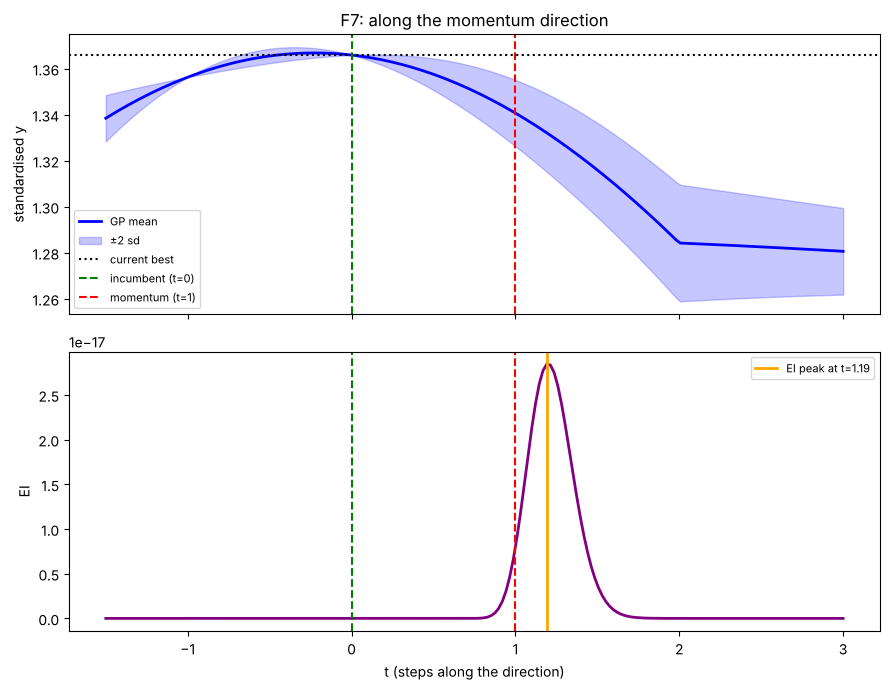

      EI peaks at t=1.19 -> [0.0809 0.1612 0.3287 0.3037 0.3136 0.6698]
      t<1 means: right direction, shorter step than momentum suggests.


array([0.0809, 0.1612, 0.3287, 0.3037, 0.3136, 0.6698])

In [13]:
def explain_direction(fn, xi=0.03, transform=None, t_range=(-1.5, 3.0)):
    """Plot GP mean/uncertainty and EI along the line through the last two best points."""
    X, y = load(fn)
    o = np.argsort(y)[::-1]
    new_best, old_best = X[o[0]], X[o[1]]
    step = new_best - old_best
    print(f"F{fn}  best now {np.round(new_best,3)} (y={y[o[0]]:.4g})")
    print(f"      before   {np.round(old_best,3)} (y={y[o[1]]:.4g})")
    print(f"      step     {np.round(step,3)}   -> momentum = {np.round(np.clip(new_best+step,0,0.999999),4)}")

    yt = transform(y) if transform else y
    yn = (yt - yt.mean()) / yt.std()
    gp = GaussianProcessRegressor(
        ConstantKernel(1.0)*Matern(length_scale=[0.2]*X.shape[1], nu=2.5),
        n_restarts_optimizer=8, random_state=0).fit(X, yn)
    ybest = yn.max()

    ts = np.linspace(*t_range, 200)
    pts = np.clip(new_best + ts[:,None]*step, 0, 1)
    mu, sd = gp.predict(pts, return_std=True)
    imp = mu - ybest - xi
    z = imp / np.maximum(sd, 1e-9)
    ei = imp*norm.cdf(z) + sd*norm.pdf(z)

    fig, ax = plt.subplots(2, 1, figsize=(9,7), sharex=True)
    ax[0].plot(ts, mu, 'b-', lw=2, label='GP mean')
    ax[0].fill_between(ts, mu-2*sd, mu+2*sd, alpha=.22, color='b', label='±2 sd')
    ax[0].axhline(ybest, color='k', ls=':', label='current best')
    ax[0].axvline(0, color='g', ls='--', label='incumbent (t=0)')
    ax[0].axvline(1, color='r', ls='--', label='momentum (t=1)')
    ax[0].set_ylabel('standardised y'); ax[0].legend(fontsize=8)
    ax[0].set_title(f'F{fn}: along the momentum direction')
    ax[1].plot(ts, ei, color='purple', lw=2)
    ax[1].axvline(0, color='g', ls='--'); ax[1].axvline(1, color='r', ls='--')
    tb = ts[ei.argmax()]
    ax[1].axvline(tb, color='orange', lw=2, label=f'EI peak at t={tb:.2f}')
    ax[1].set_xlabel('t (steps along the direction)'); ax[1].set_ylabel('EI'); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

    cand = np.clip(new_best + tb*step, 0, 0.999999)
    print(f"      EI peaks at t={tb:.2f} -> {np.round(cand,4)}")
    print("      t<1 means: right direction, shorter step than momentum suggests.")
    return cand

explain_direction(7, xi=0.03, transform=np.log)

## 9. Results after thirteen rounds

Best-so-far per function by round, the round each best arrived in, and the decider tag for every query. These are the numbers reported in the model card and the README.


Fn   start best   final best round
 1   7.7109e-16      1.99794    12
 2      0.61121     0.642964     1
 3    -0.034835  -0.00893545    11
 4      -4.0255     0.681621     4
 5       1088.9      8662.41     9
 6     -0.71426    -0.203425    12
 7        1.365      3.16217    12
 8       9.5985      9.98279    12


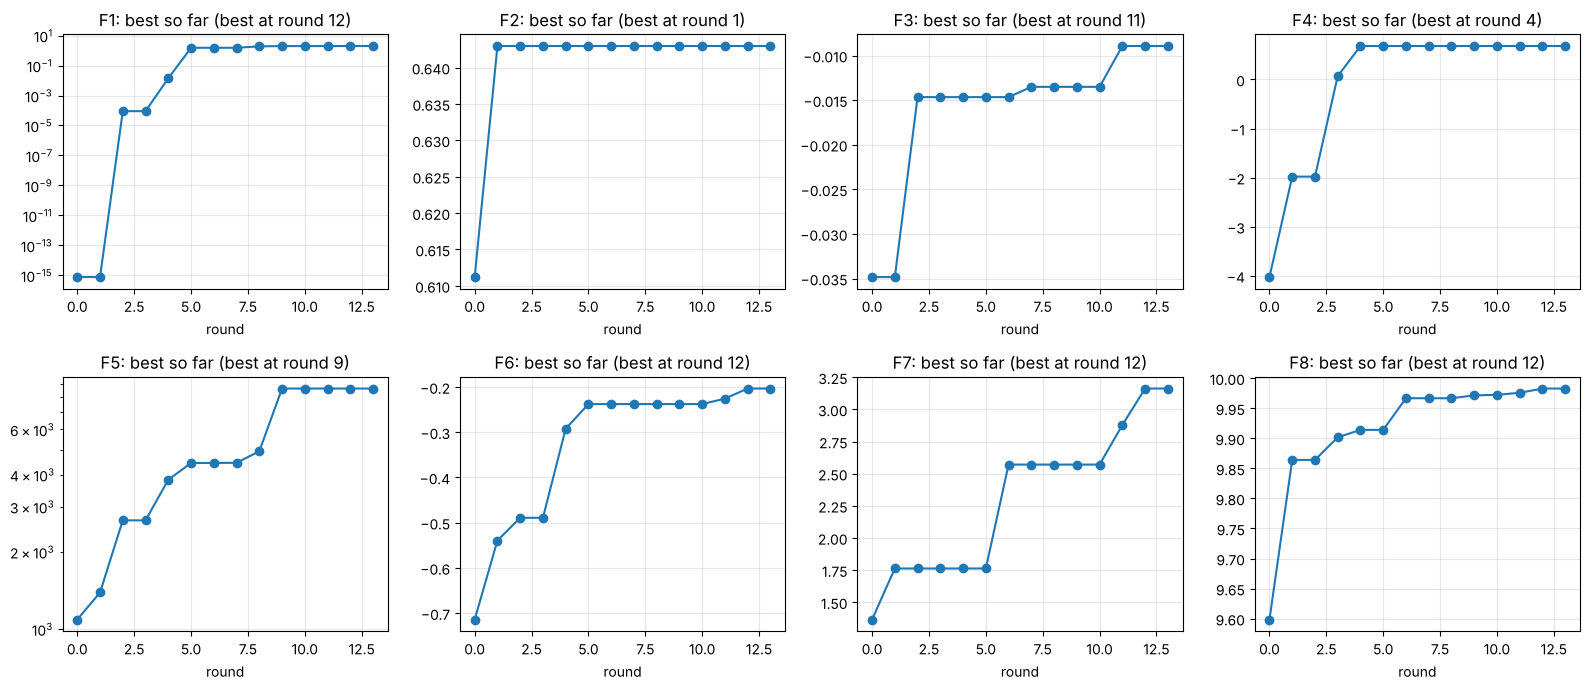


Decider tags across all 104 queries: {'surrogate': 44, 'surrogate-log': 3, 'structural': 8, 'trend': 20, 'exploration': 19, 'svm-filter': 5, 'repeat': 5}
Decider tags for the queries that produced a new best:
  F1 round  2: surrogate-log -> 9.03715e-05
  F1 round  4: trend         -> 0.014062
  F1 round  5: trend         -> 1.52696
  F1 round  8: trend         -> 1.90282
  F1 round  9: trend         -> 1.9798
  F1 round 11: trend         -> 1.99093
  F1 round 12: trend         -> 1.99794
  F2 round  1: surrogate     -> 0.642964
  F3 round  2: structural    -> -0.0146646
  F3 round  7: structural    -> -0.0135111
  F3 round 11: structural    -> -0.00893545
  F4 round  1: surrogate     -> -1.97935
  F4 round  3: surrogate     -> 0.0677701
  F4 round  4: surrogate     -> 0.681621
  F5 round  1: surrogate     -> 1388.52
  F5 round  2: surrogate-log -> 2652.84
  F5 round  4: trend         -> 3819.72
  F5 round  5: trend         -> 4440.48
  F5 round  6: trend         -> 4440.57
  F5 round 

In [14]:
START = {}
for fn in range(1, 9):
    START[fn] = float(np.load(f'{DATA}/function_{fn}/initial_outputs.npy').max())

rows = []
for fn in range(1, 9):
    best, br = START[fn], 0
    track = []
    for r, rd in enumerate(ROUNDS, start=1):
        if rd['y'][fn] > best:
            best, br = rd['y'][fn], r
        track.append(best)
    rows.append((fn, START[fn], best, br, track))

print(f"{'Fn':>2} {'start best':>12} {'final best':>12} {'round':>5}")
for fn, s, b, br, _ in rows:
    print(f"{fn:>2} {s:>12.5g} {b:>12.6g} {br:>5}")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (fn, s, b, br, track) in zip(axes.ravel(), rows):
    ax.plot(range(0, 14), [s] + track, marker='o')
    if fn in (1, 5):
        ax.set_yscale('log')
    ax.set_title(f"F{fn}: best so far (best at round {br})")
    ax.set_xlabel("round"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

from collections import Counter
print("\nDecider tags across all 104 queries:", dict(Counter(t for r in DECIDED_BY.values() for t in r.values())))
print("Decider tags for the queries that produced a new best:")
for fn in range(1, 9):
    best = START[fn]
    for r, rd in enumerate(ROUNDS, start=1):
        if rd['y'][fn] > best:
            best = rd['y'][fn]
            print(f"  F{fn} round {r:>2}: {DECIDED_BY[r][fn]:<13} -> {best:.6g}")
